In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
%cd '/content/drive/My Drive/2_PHDWork/1_Objective-I/8_ScalingErrorEstimation/'

In [3]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pickle
import seaborn as sns
from scipy.stats import skew, kurtosis
from scipy.stats import zscore
import scipy.stats as stats
from sklearn.mixture import GaussianMixture
import pandas as pd
from matplotlib.lines import Line2D

In [4]:
"""
  Method to read the error values.

  Parameter:
        filenames: the individual WSI error values
        errorvaluepath: the path to the error value files.
  Return:
        s_error_values: the error values correspodning to simple boundary scaling.
        p_error_values: the error values correspodning to proposed method.
"""

"""
  006f6aa35a78965c92fffd1fbd53a058_mask.pkl
  00ca0c23961b5510be46c917be11c43e_mask.pkl

  These files should be avoided.
"""
def get_error_values(files_names,errorvaluepath):
  s_error_values = []
  p_error_values = []
  if(len(files_names) > 0):
    index = 0
    print(f'\tCollecting values from a total of {len(files_names)} files ...')
    while(index < len(files_names)):
      file_name = files_names[index]
      if(index < 3):
        print(f'\t\t{index}: Processing the WSI file {file_name}')
      fname = os.path.join(errorvaluepath,file_name)
      with open(fname, "rb") as f:
        error = pickle.load(f)
        s_error_values.append(error[0])
        p_error_values.append(error[2])

      index += 1

  return s_error_values,p_error_values

In [5]:
"""
  Method to generate the histogram and the distribution.

  Parameter:
        img_error_values: the error values
  Return:
        None.
"""
def generate_histogram_and_distribution(img_error_values):
  limit = len(img_error_values)
  fig1, axs1 = plt.subplots(1, 3, figsize=(18,5))

  index = 0
  distributions = [stats.norm,stats.rice]
  for c in range(3):
    cleaned_values, outliers = clean_and_prepare_data(img_error_values[index])
    # perform_visualization_analysis(cleaned_values, ax1=axs1[0,c])

    parameters = []
    for distribution in distributions:
      if(distribution.name == 'rice'):
        parameters.append(distribution.fit(cleaned_values,floc=0))
      else:
        parameters.append(distribution.fit(cleaned_values))

    distribution_comparison(cleaned_values,distributions,parameters,ax1=axs1[c])

    axs1[c].set_title(f'WSI-{index+1}')
    axs1[c].set_ylabel('Probability Density')
    # axs1[1,c].set_ylabel('Frequency')
    axs1[c].set_xlabel('Boundary Scaling Error (E)')
    # axs1[1,c].set_xlabel('Scaling Error (E)')

    handles, labels = axs1[c].get_legend_handles_labels()

    # Custom legend handle for the histogram
    hist_legend = Line2D(
                        [0], [0],
                        color='gray',
                        linewidth=2,
                        label='data histogram'
                        )

    # Add all legend handles together
    axs1[c].legend(handles=[hist_legend] + handles, loc='best')
    # axs1[c].legend()

    index += 1
    if(index >= limit):
        break

  fig1.savefig('ImageSpecific_Histogram.pdf', bbox_inches='tight', dpi=300)
  plt.show()

  return

"""
  Method to perform visualization analysis. It visualises histogram, KDE, ECDF.

  Parameter:
        error_values: the error values
        ax1 to ax4: the subplot handles.
  Return:
        None.
"""
def perform_visualization_analysis(error_values, ax1=None, ax2=None, ax3=None, ax4=None):

  # Plot histogram
  if(ax1):
    sns.histplot(error_values, ax=ax1, bins=len(np.unique(error_values)), color='skyblue', edgecolor='skyblue', label='_nolegend_') #label='simple-scaling')

  # Plot KDE
  if(ax2):
    sns.kdeplot(error_values, ax=ax2, color='darkblue', linewidth=2)

  # Plot ECDF
  if(ax3):
    x = np.sort(error_values)
    y = np.arange(1, len(x) + 1) / len(x)
    ax3.step(x, y, where='post', color='blue', linestyle='-')

  # Plot Q-Q Plot vs Normal
  if(ax4):
    stats.probplot(error_values, dist="norm", plot=ax4)

  return


"""
  Method to perform the visualization of histogram of both scaling and proposed
  method error values

  Parameter:
        error_values: the error values of simple boundary scaling.
        cleaned_values_p: the error values of proposed method.
        ax1 to ax4: the subplot handles.
  Return:
        None.
"""
def perform_visualization_analysis_of_two(error_values, cleaned_values_p, ax1=None, ax2=None, ax3=None, ax4=None):

  # Plot histogram
  if(ax1):
    sns.histplot(error_values, ax=ax1, bins=len(np.unique(error_values)), color='skyblue', edgecolor='skyblue', label='_nolegend_')     #edgecolor='black', label='simple-scaling')
    sns.histplot(cleaned_values_p, ax=ax1, bins=len(np.unique(cleaned_values_p)), color='red', edgecolor='red', label='_nolegend_') #edgecolor='black', label = 'proposed-method')

  # Plot KDE
  if(ax2):
    sns.kdeplot(error_values, ax=ax2, color='darkblue', linewidth=2, label='simple-scaling')
    sns.kdeplot(cleaned_values_p, ax=ax2, color='red', linewidth=2, label = 'proposed-method')

  # Plot ECDF
  if(ax3):
    x = np.sort(error_values)
    y = np.arange(1, len(x) + 1) / len(x)
    ax3.step(x, y, where='post', color='blue', linestyle='-', label='simple-scaling')

    x = np.sort(cleaned_values_p)
    y = np.arange(1, len(x) + 1) / len(x)
    ax3.step(x, y, where='post', color='red', linestyle='-', label = 'proposed-method')

  # Plot Q-Q Plot vs Normal
  if(ax4):
    stats.probplot(error_values, dist="norm", plot=ax4)

  return

In [6]:
"""
  Methods to perform the different analysis.
"""
def perform_entire_value_candidate_distribution_analysis(img_error_values):
  """
    Step-1: Collecting all the values from different files into a single array
  """
  error_values = []
  for error_value in img_error_values:
    error_values.extend(error_value)

  cleaned_values, outliers = clean_and_prepare_data(error_values)

  distributions = [stats.norm,stats.rice]
  parameters = []

  for distribution in distributions:
    if(distribution.name == 'rice'):
      parameters.append(distribution.fit(cleaned_values,floc=0))
    else:
      parameters.append(distribution.fit(cleaned_values))

  fig, axs = plt.subplots(1, 1, figsize=(8, 8))
  results = distribution_comparison(cleaned_values,distributions,parameters,ax1=axs)
  axs.set_title('Candidate Distribution Comparison')
  axs.legend()
  plt.grid(True)
  plt.show()

  df = pd.DataFrame(results).sort_values(by='AIC')
  print(df[['Distribution', 'AIC', 'BIC', 'KS Statistic', 'KS p-value', 'AD Statistic', 'AD Critical Values', 'AD Significance Levels']])
  # print(df[['Distribution','AIC', 'BIC', 'KS Statistic', 'KS p-value', 'AD Statistic', 'AD Critical Values', 'AD Significance Levels','Parameters']])

  return

def perform_image_specific_candidate_distribution_analysis(img_error_values):
  limit = len(img_error_values)
  fig1, axs1 = plt.subplots(10, 10, figsize=(40, 40))
  index = 0
  distributions = [stats.norm,stats.rice]
  overall_results = []

  for r in range(10):
    for c in range(10):
      cleaned_values, outliers = clean_and_prepare_data(img_error_values[index])
      parameters = []

      for distribution in distributions:
        if(distribution.name == 'rice'):
          parameters.append(distribution.fit(cleaned_values,floc=0))
        else:
          parameters.append(distribution.fit(cleaned_values))

      results = distribution_comparison(cleaned_values,distributions,parameters,ax1=axs1[r,c])
      overall_results.append(results)

      axs1[r,c].set_title(f'Image-{index+1}')
      if(c > 0):
        axs1[r,c].set_ylabel('')

      if(c == 0 and r == 0):
        axs1[r,c].legend()

      index += 1
      if(index >= limit):
        break
    if(index >= limit):
      break

  plt.grid(True)
  plt.show()

  analyse_distribution_comparison_results(overall_results)

  # for i in range(len(overall_results)):
  #   df = pd.DataFrame(overall_results[i]).sort_values(by='AIC')
  #   print(f'------------ Image-{i+1} ---------------')
  #   # print(df[['Distribution', 'AIC', 'BIC', 'KS Statistic', 'KS p-value', 'AD Statistic', 'AD Critical Values', 'AD Significance Levels']])
  #   print(df[['Distribution','AIC', 'BIC', 'KS Statistic', 'KS p-value', 'AD Statistic', 'AD Critical Values', 'AD Significance Levels','Parameters']])
  #   print(f'----------------------------------------')

  return

def distribution_comparison(error_values,distribution,parameters,ax1=None):
  x = np.linspace(min(error_values), max(error_values), 100)
  sns.histplot(error_values, ax=ax1, stat='density', bins=len(np.unique(error_values)), color='gray', edgecolor='gray', label='_nolegend_')
  n = len(error_values) # Sample size
  results = []

  for i in range(len(distribution)):
    # Overlaying distribution over the histogram.
    params = parameters[i]
    pdf = distribution[i].pdf(x, *params)
    if(distribution[i].name == "norm"):
      lab = "Gaussian"
    elif(distribution[i].name == "rice"):
      lab = "Rice"
    else:
      lab = distribution[i].name == "norm"

    ax1.plot(x, pdf, label=lab,linewidth=2)

    # Computing the Akaike Information Criterion (AIC) and Bayesian Information Criterion (BIC)
    k = len(params) # Number of parameters
    log_likelihood = np.sum(distribution[i].logpdf(error_values, *params))
    aic = 2 * k - 2 * log_likelihood
    bic = k * np.log(n) - 2 * log_likelihood

    # Kolmogorov–Smirnov (KS)
    ks_stat, ks_pvalue = stats.kstest(error_values, distribution[i].name, args=params)

    # Anderson-Darling Test (only supports a few distributions)
    try:
        ad_result = stats.anderson(error_values, dist=distribution[i].name)
        ad_stat = ad_result.statistic
        ad_crit = ad_result.critical_values
        ad_sig = ad_result.significance_level
    except Exception as e:
        ad_stat = None
        ad_crit = None
        ad_sig = None

    results.append({
        'Distribution': distribution[i].name,
        'AIC': aic,
        'BIC': bic,
        'Parameters': params,
        'KS Statistic': ks_stat,
        'KS p-value': ks_pvalue,
        'AD Statistic': ad_stat,
        'AD Critical Values': ad_crit,
        'AD Significance Levels': ad_sig
    })

  return results


def analyse_distribution_comparison_results(results):
  limit = len(results)
  rice_dist_data = []
  gaussian_dist_data = []
  for i in range(limit):
    res_data = results[i]
    if(res_data[0]['Distribution'] == 'rice'):
      rice_dist_data.append(res_data[0])
      gaussian_dist_data.append(res_data[1])
    else:
      gaussian_dist_data.append(res_data[0])
      rice_dist_data.append(res_data[1])

  plot_goodness_of_fit(rice_dist_data,gaussian_dist_data)
  plot_rice_parameters(rice_dist_data)

  return


def plot_goodness_of_fit(rice,norm):
  fig, axs = plt.subplots(1, 4, figsize=(30, 6))

  """
    Populating the required data
  """
  limit = len(rice)
  r_aic = []
  r_bic = []
  r_ks_stat = []
  r_ks_pvalue = []
  n_aic = []
  n_bic = []
  n_ks_stat = []
  n_ks_pvalue = []

  for i in range(limit):
    r_dict = rice[i]
    n_dict = norm[i]
    r_aic.append(r_dict['AIC'])
    r_bic.append(r_dict['BIC'])
    r_ks_stat.append(r_dict['KS Statistic'])
    r_ks_pvalue.append(r_dict['KS p-value'])
    n_aic.append(n_dict['AIC'])
    n_bic.append(n_dict['BIC'])
    n_ks_stat.append(n_dict['KS Statistic'])
    n_ks_pvalue.append(n_dict['KS p-value'])

  x = np.arange(1,limit*2, 2)
  bar_width = 0.6
  x1 = x - bar_width / 2
  x2 = x + bar_width / 2

  axs[0].bar(x1, r_aic, width=bar_width, label='rice', color='skyblue')
  axs[0].bar(x2, n_aic, width=bar_width, label='norm', color='salmon')
  axs[0].set_title('AIC Comparison')
  axs[0].legend()

  axs[1].bar(x1, r_bic, width=bar_width, label='rice', color='skyblue')
  axs[1].bar(x2, n_bic, width=bar_width, label='norm', color='salmon')
  axs[1].set_title('BIC Comparison')
  axs[1].legend()

  axs[2].bar(x1, r_ks_stat, width=bar_width, label='rice', color='skyblue')
  axs[2].bar(x2, n_ks_stat, width=bar_width, label='norm', color='salmon')
  axs[2].set_title('KS Statistics Comparison')
  axs[2].legend()

  axs[3].bar(x1, r_ks_pvalue, width=bar_width, label='rice', color='skyblue')
  axs[3].bar(x2, n_ks_pvalue, width=bar_width, label='norm', color='salmon')
  axs[3].set_yscale('log')
  axs[3].set_title('KS p-value Comparison')
  axs[3].legend()

  # After defining x = np.arange(1, limit * 2, 2)
  label_indices = [0, 24, 49, 74, limit-1]  # indices for Image 1, 50, 100
  label_positions = [x[i] for i in label_indices]
  label_texts = [f'{i+1}' for i in label_indices]

  for ax in axs:
    ax.set_xticks(label_positions)
    ax.set_xticklabels(label_texts)
    ax.set_xlabel('Images')

  fig.suptitle("Goodness of fit")
  plt.show()

  return

import matplotlib.pyplot as plt
import numpy as np

def plot_rice_parameters(rice):
  # Extract parameters
  b_value = []
  # loc_value = []
  scale_value = []

  for r_dict in rice:
    b, loc, scale = r_dict['Parameters']
    b_value.append(round(b, 2))
    # loc_value.append(round(loc, 2))
    scale_value.append(round(scale, 2))

  limit = len(rice)
  indices = np.arange(limit)

  fig, axs = plt.subplots(1, 2, figsize=(15, 7))


  def plot_centered_barh(ax, values, title, x_label, y_label, color_map=None):
    # Color coding
    if color_map:
        colors = [color_map(v) for v in values]
    else:
        colors = 'skyblue'

    # Plot bars
    ax.barh(indices, values, color=colors)

    # Center line at x=0
    ax.axvline(0, color='black', linewidth=1)

    # Force symmetric x-axis around zero
    max_val = max(abs(min(values)), abs(max(values)))
    ax.set_xlim(-max_val * 1.1, max_val * 1.1)

    # Y-axis setup
    ax.invert_yaxis()
    ax.set_xlabel(x_label)
    ax.set_ylabel(y_label)
    ax.set_title(title)
    ax.grid(True, axis='x', linestyle='--', alpha=0.5)

    return

  # Panel 1: b values
  plot_centered_barh(axs[0], b_value, 'a', 'b-values', 'Images')

  # Panel 2: loc values
  # plot_centered_barh(axs[1], loc_value, 'b', 'loc-values','Images', color_map=lambda v: 'green' if v >= 0 else 'red')

  # Panel 3: scale values
  plot_centered_barh(axs[1], scale_value, 'b', 'scale-values','Images', color_map=lambda v: 'green' if v >= 0 else 'red')

  fig.suptitle("Rice Distribution Parameters Across Images", fontsize=16)
  plt.tight_layout(rect=[0, 0, 1, 0.95])
  plt.show()

  return

In [7]:
"""
  Methods for pre-processing the error values.
"""
def clean_and_prepare_data(error_values,abs=True):
  initial_error_values = np.concatenate(error_values)

  # Remove outliers
  cleaned_error_values, outliers= remove_outliers(initial_error_values,abs=abs)

  return cleaned_error_values, outliers

def remove_outliers(data, abs=True):
  z_scores = np.abs(zscore(data))
  # Keep data within threshold
  if(abs):
    """
       Filtering out zeors as it would affect Rice distribution.
    """
    filtered_data = remove_zeros(np.abs(data[z_scores < 3]))
  else:
    filtered_data = data[z_scores < 3]
  outliers = data[z_scores >= 3]

  return filtered_data, outliers

def remove_zeros(data):
  return data[data != 0]

In [8]:
def perform_exploratory_analysis(error_values):
  print(f'\tPerforming exploratory analysis ...')
  print(f'\t\tTotal Samples : {error_values.shape[0]}')
  print(f'\t\tRange         : [{np.min(error_values)},{np.max(error_values)}]')
  print(f'\t\tMean          : {np.mean(error_values)}')
  print(f'\t\tStd Dev       : {np.std(error_values)}')
  print(f'\t\tSkewness      : {skew(error_values)}')
  print(f'\t\tKurtosis      : {kurtosis(error_values)}')

  return

In [9]:
def generate_impact_plot(s_error_values):
  limit = len(s_error_values)
  fig1, axs1 = plt.subplots(1, 3, figsize=(18,5))

  index = 0
  for c in range(3):
    cleaned_values_s, outliers = clean_and_prepare_data(s_error_values[index],abs=False)
    perform_visualization_analysis(cleaned_values_s, ax1=axs1[c])

    axs1[c].set_title(f'WSI-{index+1}')
    axs1[c].set_ylabel('Frequency')
    axs1[c].set_xlabel('Signed Boundary Scaling Error (E)')

    # Custom legend handle for the histogram
    hist_legend1 = Line2D(
                        [0], [0],
                        color='skyblue',
                        linewidth=1.5,
                        label='simple-scaling'
                        )

    # Add all legend handles together
    axs1[c].legend(handles=[hist_legend1], loc='best')

    index += 1
    if(index >= limit):
        break

  fig1.savefig('Impact_Analysis.pdf', bbox_inches='tight', dpi=300)
  plt.show()

  return

In [10]:
def generate_scaled_and_proposed_comparison(s_error_values, p_error_values):
  limit = len(s_error_values)
  fig1, axs1 = plt.subplots(1, 3, figsize=(18,5))

  index = 0
  for c in range(3):
    cleaned_values_s, outliers = clean_and_prepare_data(s_error_values[index],abs=False)
    cleaned_values_p, outliers = clean_and_prepare_data(p_error_values[index],abs=False)

    perform_visualization_analysis_of_two(cleaned_values_s, cleaned_values_p, ax1=axs1[c])

    axs1[c].set_title(f'WSI-{index+1}')
    axs1[c].set_ylabel('Frequency')
    axs1[c].set_xlabel('Signed Boundary Scaling Error (E)')
    axs1[c].legend(handles=[
    Line2D([0], [0], color='skyblue', linewidth=1.5, label='simple-scaling'),
    Line2D([0], [0], color='red', linewidth=1.5, label='proposed-method')
    ])

    index += 1
    if(index >= limit):
        break

  fig1.savefig('Simple_Proposed_comparison.pdf', bbox_inches='tight', dpi=300)
  plt.show()

  return

In [11]:
"""
  The entry function of this file

  Parameter:
      errorvaluepath: Path to the error values.
  Return:
      None
"""
def entry_fun(errorvaluepath):
  if os.path.isfile(errorvaluepath):
    files_names = [os.path.basename(errorvaluepath)]
    errorvaluepath = os.path.dirname(errorvaluepath)
  elif os.path.isdir(errorvaluepath):
    files_names = sorted(os.listdir(errorvaluepath),reverse=True)
  else:
    print("Path does not exist or is something else.")
    files_names = []

  """
    Step-1: Reading the error values from the respective files.
  """
  s_error_values, p_error_values = get_error_values(files_names,errorvaluepath)

  generate_impact_plot(s_error_values)
  perform_entire_value_candidate_distribution_analysis(s_error_values)
  generate_histogram_and_distribution(s_error_values)
  generate_scaled_and_proposed_comparison(s_error_values, p_error_values)

  return

In [12]:
def main():
  errorvaluepath = "./1_ErrorValues/1_Inter_Area/Scale_16.0/"

  entry_fun(errorvaluepath)
  return

		0: Processing the WSI file 05a377208625fce1afdc4878e3185ca4_mask.pkl
		1: Processing the WSI file 059cbf902c5e42972587c8d17d49efed_mask.pkl
		2: Processing the WSI file 059ab4f2222a3231845f048a63036083_mask.pkl


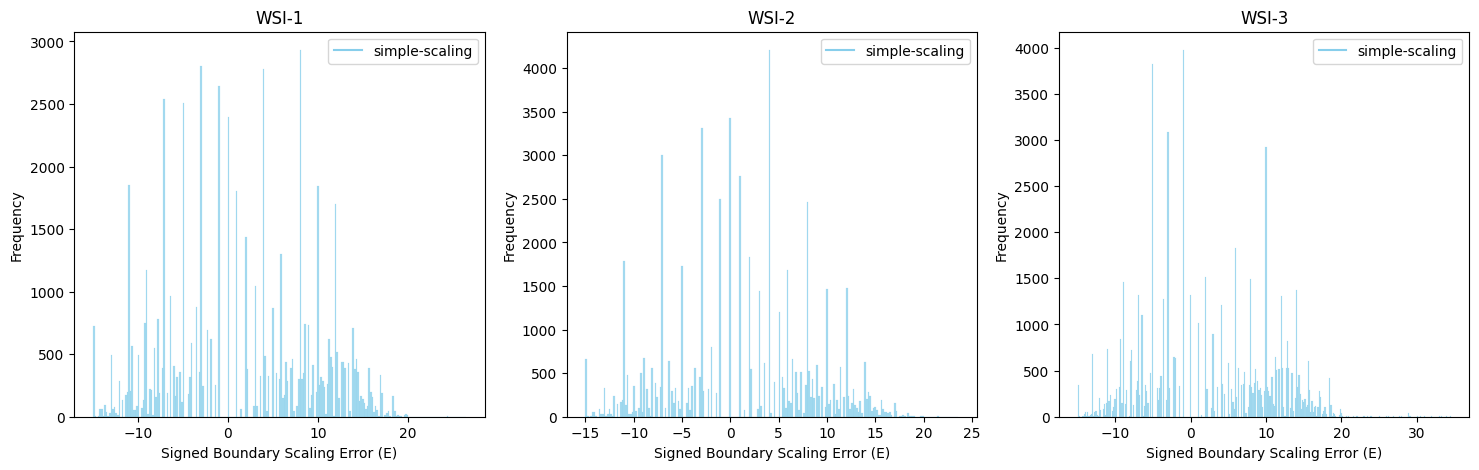

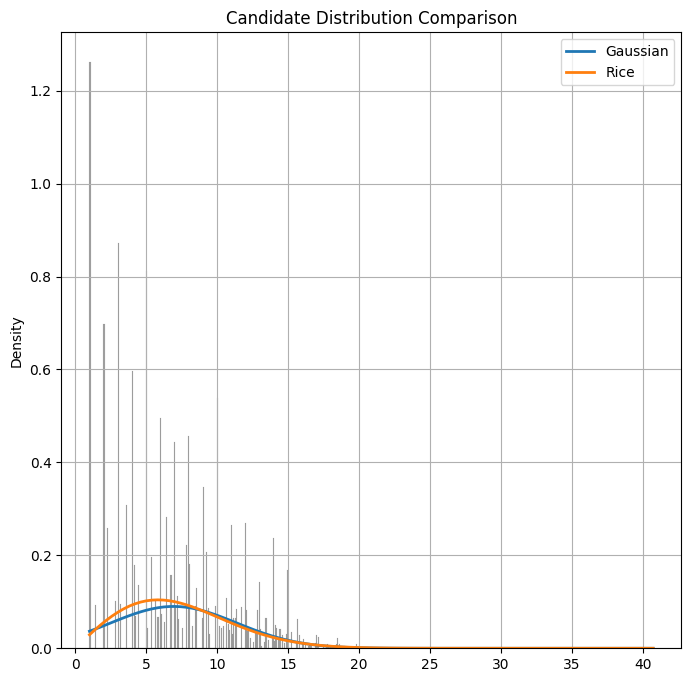

  Distribution           AIC           BIC  KS Statistic  KS p-value  \
1         rice  3.012937e+07  3.012941e+07      0.125672         0.0   
0         norm  3.082233e+07  3.082236e+07      0.090165         0.0   

   AD Statistic                   AD Critical Values  \
1           NaN                                 None   
0  54228.378872  [0.576, 0.656, 0.787, 0.918, 1.092]   

        AD Significance Levels  
1                         None  
0  [15.0, 10.0, 5.0, 2.5, 1.0]  


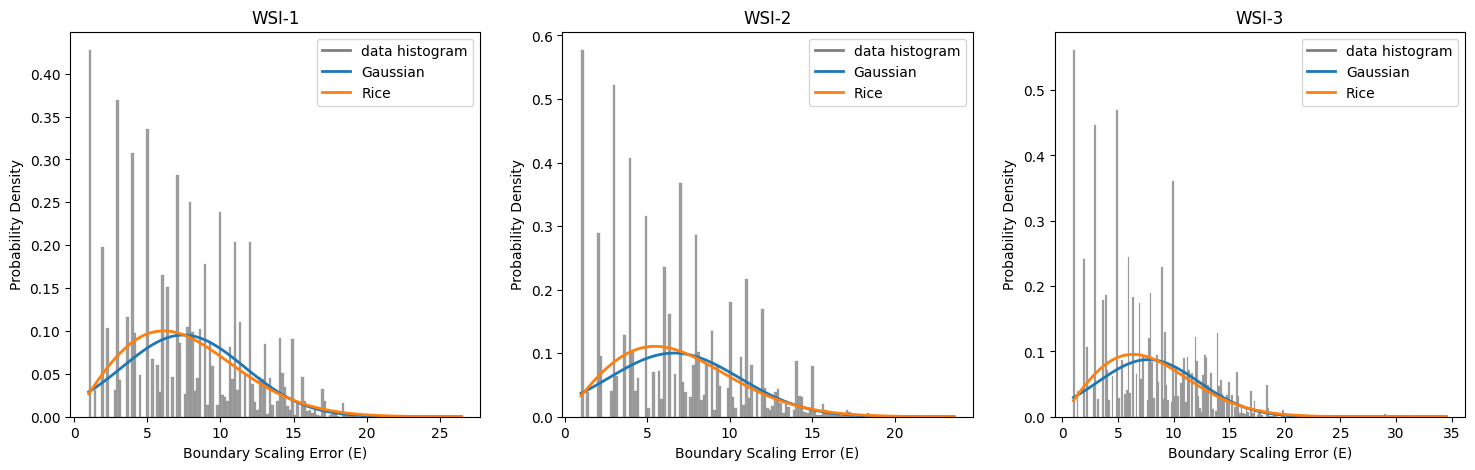

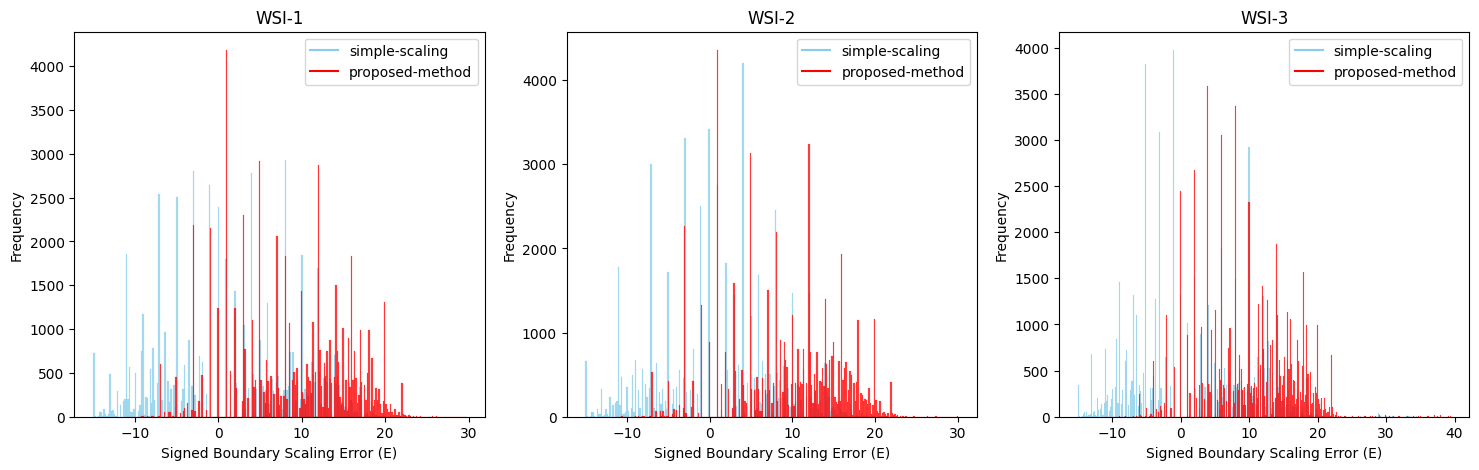

In [13]:
main()